<a href="https://colab.research.google.com/github/Roheya20/First-session/blob/main/Week1_Data_Cleaning_Roheya_Touray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Roheya Touray

Week1: Data cleaning and analysis


In [118]:
import pandas as pd


In [119]:
df = pd.read_csv('applicants.csv')

In [120]:
df.shape

(68, 7)

In [121]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Grace Njeri,grace.njeri25@gmail.com,0788963003,Web Development,ALU,2026-05-25,Selected
1,Fatou Jallow,fatou.jallow44@gmail.com,0788985669,Machine Learning,ALU,2026-06-13,Rejected
2,Sara Ahmed,sara.ahmed35@gmail.com,0788982709,Web Development,ALU,2026-06-04,Under Review
3,Aminata Koroma,aminata.koroma16@gmail.com,0788150626,AI,ALU,2026-05-16,Rejected
4,Linda Brown,linda.brown31@gmail.com,0788851138,Machine Learning,ALU,2026-05-31,Selected


In [122]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Applicant Name    67 non-null     object
 1   Email             67 non-null     object
 2   Phone             68 non-null     object
 3   Domain Applied    68 non-null     object
 4   University        65 non-null     object
 5   Application Date  68 non-null     object
 6   Status            67 non-null     object
dtypes: object(7)
memory usage: 3.8+ KB


In [123]:
df.isnull().sum()

,0
Applicant Name,1
Email,1
Phone,0
Domain Applied,0
University,3
Application Date,0
Status,1


In [124]:
df.duplicated().sum()

np.int64(3)

The dataset has 68 rows and 7 columns. Email has 1 missing value, University has 3 missing values, Applicant name has 1 missing value, Status has 1 missing value, there are 3 exact duplicate rows.


In [125]:
df = df.dropna(subset= ['Applicant Name'])

In [126]:
df.isnull().sum()

,0
Applicant Name,0
Email,1
Phone,0
Domain Applied,0
University,2
Application Date,0
Status,1


I dropped the row with missing Application Name because a nameless application isn't for outreach

In [127]:
df = df.dropna(subset=['Email'])

In [128]:
df.isnull().sum()

,0
Applicant Name,0
Email,0
Phone,0
Domain Applied,0
University,2
Application Date,0
Status,1


I dropped rows with missing email beacuase an application without an email can't be reached.

In [129]:
df['University'] = df['University'].fillna('Not specified')

In [130]:
df.isnull().sum()

,0
Applicant Name,0
Email,0
Phone,0
Domain Applied,0
University,0
Application Date,0
Status,1


I filled missing University with 'Not Specified' instead of dropping it, since it's not essential to determining applcation status.

In [131]:
df['Status']= df['Status'].fillna('Under Review')

In [132]:
df.isnull().sum()

,0
Applicant Name,0
Email,0
Phone,0
Domain Applied,0
University,0
Application Date,0
Status,0


In [133]:
df = df.drop_duplicates(subset=['Email'], keep='first')

In [134]:
df.duplicated().sum()

np.int64(0)

I had 3 duplicates, after dropping  the number of duplicates beacame 0. I chose to use email because with the email you can check duplicate applications by the same email.

In [135]:
domain_mapping ={
    'web dev': 'Web Development',
    'webdev': 'Web Development',
    'web development': 'Web Development',
    'web Development': 'Web Development',
    'WEB DEV': 'Web Development',
    'data sci': 'Data Science',
    'datascience':'Data Science',
    'data science':'Data Science',
    'cyber security':'Cybersecurity',
    'cyber sec': 'Cybersecurity',
    'app development':'App Development',
    'app dev':'App Development',
    'mobile app':'App Development',
    'ai':'AI',
    'ai/ml':'AI',
    'machine learning':'AI',
    'ml':'AI'
}


In [136]:
df['Domain Original'] = df['Domain Applied']

In [137]:
df['Domain Applied'] = df['Domain Applied'].astype(str).str.strip().str.lower()

In [138]:
df['Domain Applied'] = df['Domain Applied'].replace(domain_mapping)

In [139]:
def fix_title(x):
  if x == 'AI' or x == 'ai':
    return 'AI'
  if x == 'nan' or x =='' or x == 'None':
    return 'Unknown'
  return str(x).title()

In [140]:
df['Domain Applied'] = df['Domain Applied'].apply(fix_title)

In [141]:
print(df[df['Domain Applied'] == 'University of The Gambia'])

Empty DataFrame
Columns: [Applicant Name, Email, Phone, Domain Applied, University, Application Date, Status, Domain Original]
Index: []


In [142]:
print(df['Domain Applied'].isnull().sum())

0


In [143]:
df['Status'] = df['Status'].str.strip().str.title()

In [144]:
df['Application Date'] = pd.to_datetime(df['Application Date'], errors='coerce')

In [145]:
df['Application Date'].isnull().sum()

np.int64(6)

In [146]:
df['Phone'] = df['Phone'].str.replace('-', '', regex=False).str.replace('', '', regex=False)

In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 63 entries, 0 to 67
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    63 non-null     object        
 1   Email             63 non-null     object        
 2   Phone             63 non-null     object        
 3   Domain Applied    63 non-null     object        
 4   University        63 non-null     object        
 5   Application Date  57 non-null     datetime64[ns]
 6   Status            63 non-null     object        
 7   Domain Original   63 non-null     object        
dtypes: datetime64[ns](1), object(7)
memory usage: 4.4+ KB


In [148]:
df.shape

(63, 8)

In [149]:
df.isnull().sum()

,0
Applicant Name,0
Email,0
Phone,0
Domain Applied,0
University,0
Application Date,6
Status,0
Domain Original,0


In [150]:
df.duplicated().sum()

np.int64(0)

Data Quality Summary
Starting dataset: 68 rows, 7 columns

Issues found:
- 1 missing value in Application Name, 1 missing value in Email, 3 missing values in university, 1 missing value in status
- 3 exact duplicate rows, plus 3 additional duplicate applications Identified my matching Email.
- Domain Applied contained inconsistent spellings and capitalisation, including variations such as web dev, Web dev, WEB DEV.
- Application date values used inconsistent formats and needed to be converted to a proper datetime type
- Phone numbers contained inconsistent spacing and dash formatting.
- Status values had inconsistent capitalisation, such as Selected, selected, and SELECTED

Actions taken:
- Dropped 1 row with missing Application Name (unusable without identification)
- Filled missing University with "Not Specified" (non-critical field)
-Filled missing Status with "Under Review" (default for unprocessed applications)
- Removed 6 duplicate rows total (3 exact, 3 by matching email)
- Converted Application Date to the proper datetime format.
- Cleaned phone number formatting for consistency

Final dataset: 63 rows, 7 columns, no missing values in critical fields, no duplicates, consistent formatting throughout.

In [151]:
df.to_csv('applicants_cleaned.csv', index=False)

#week 2 - Exploratory Data Analysis: NextGenLearners Applicant Insights


In [152]:
import pandas as pd


In [153]:
import matplotlib.pyplot as plt


In [154]:
import seaborn as sns

In [155]:
df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

In [156]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    63 non-null     object        
 1   Email             63 non-null     object        
 2   Phone             63 non-null     object        
 3   Domain Applied    63 non-null     object        
 4   University        63 non-null     object        
 5   Application Date  57 non-null     datetime64[ns]
 6   Status            63 non-null     object        
 7   Domain Original   63 non-null     object        
dtypes: datetime64[ns](1), object(7)
memory usage: 4.1+ KB


In [157]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,Domain Original
0,Grace Njeri,grace.njeri25@gmail.com,0788963003,Web Development,ALU,2026-05-25,Selected,Web Development
1,Fatou Jallow,fatou.jallow44@gmail.com,0788985669,AI,ALU,2026-06-13,Rejected,Machine Learning
2,Sara Ahmed,sara.ahmed35@gmail.com,0788982709,Web Development,ALU,2026-06-04,Under Review,Web Development
3,Aminata Koroma,aminata.koroma16@gmail.com,0788150626,AI,ALU,2026-05-16,Rejected,AI
4,Linda Brown,linda.brown31@gmail.com,0788851138,AI,ALU,2026-05-31,Selected,Machine Learning


In [158]:
df.shape

(63, 8)

In [159]:
df.isnull().sum()

,0
Applicant Name,0
Email,0
Phone,0
Domain Applied,0
University,0
Application Date,6
Status,0
Domain Original,0


Four required Questions
1. Which domain received the most applicants?
2. What is the distribution of application statuses?
3. Which universities have the most applicants?
4. How do applications change over time?

Bonus Question

5. Which domains have the highest number of successful applications?

In [160]:
domain_counts = df['Domain Applied'].value_counts()

In [161]:
print(domain_counts)

Domain Applied
AI                          28
Cybersecurity               12
Web Development             11
Data Science                11
University Of The Gambia     1
Name: count, dtype: int64


In [162]:
plt.figure(figsize=(98, 5))

<Figure size 9800x500 with 0 Axes>

<Figure size 9800x500 with 0 Axes>

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'AI'),
  Text(1, 0, 'Cybersecurity'),
  Text(2, 0, 'Web Development'),
  Text(3, 0, 'Data Science'),
  Text(4, 0, 'University Of The Gambia')])

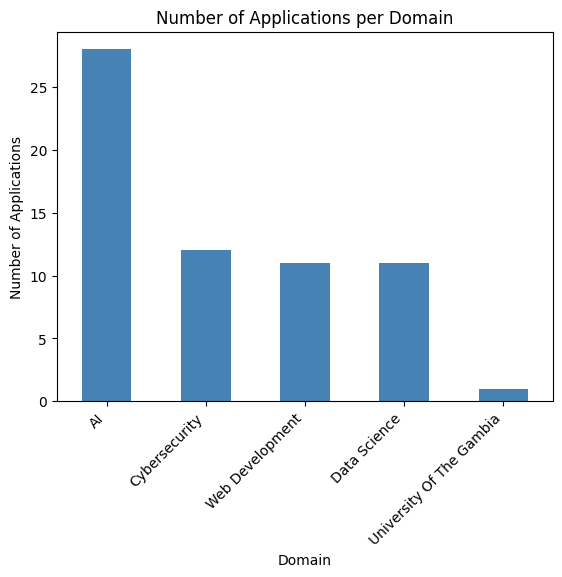

In [163]:
domain_counts.plot(kind = 'bar', color = 'steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation = 45, ha = 'right')

In [164]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [165]:
plt.show()

AI received the highest number of applications (28), while the University of The Gambis received the lowest number(1). AI received received more than twice as many applications as any other domain.

In [166]:
df['Application Month'] = df['Application Date'].dt.to_period('M')


In [167]:
monthly_trend = df.groupby('Application Month').size()

In [168]:
print(monthly_trend)

Application Month
2026-05    30
2026-06    27
Freq: M, dtype: int64


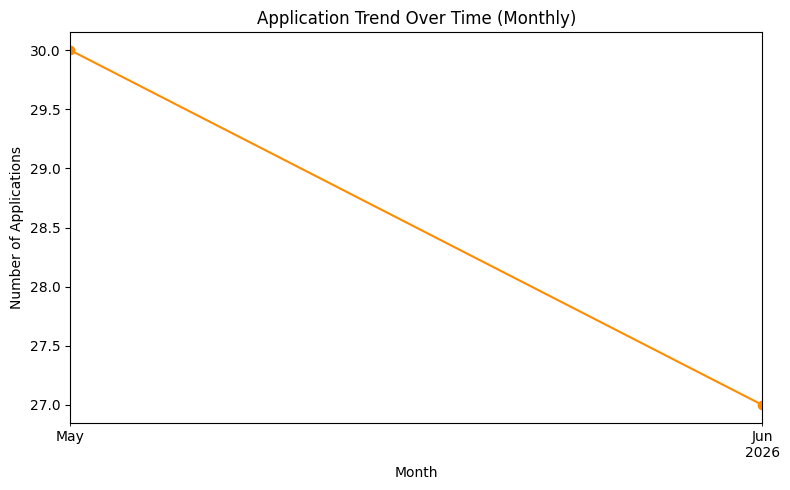

In [169]:
plt.figure(figsize=(8, 5))
monthly_trend.plot(kind='line', marker ='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

The number of applications decreased slightly over time, dropping from 30 applications in May 2026 to 27 applications in June 2026. This suggests a modest downward trend in application submissions during the period analyzed.

In [170]:
status_counts = df['Status'].value_counts()
print(status_counts)

Status
Selected        32
Under Review    16
Rejected        15
Name: count, dtype: int64


In [171]:
status_by_domain = pd.pivot_table(
    df,
    index = 'Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)


In [172]:
print(status_by_domain)

Status                    Rejected  Selected  Under Review
Domain Applied                                            
AI                              11        12             5
Cybersecurity                    1         9             2
Data Science                     2         5             4
University Of The Gambia         0         0             1
Web Development                  1         6             4


In [173]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1),
axis=0) * 100
print(status_by_domain_pct.round(1))

Status                    Rejected  Selected  Under Review
Domain Applied                                            
AI                            39.3      42.9          17.9
Cybersecurity                  8.3      75.0          16.7
Data Science                  18.2      45.5          36.4
University Of The Gambia       0.0       0.0         100.0
Web Development                9.1      54.5          36.4


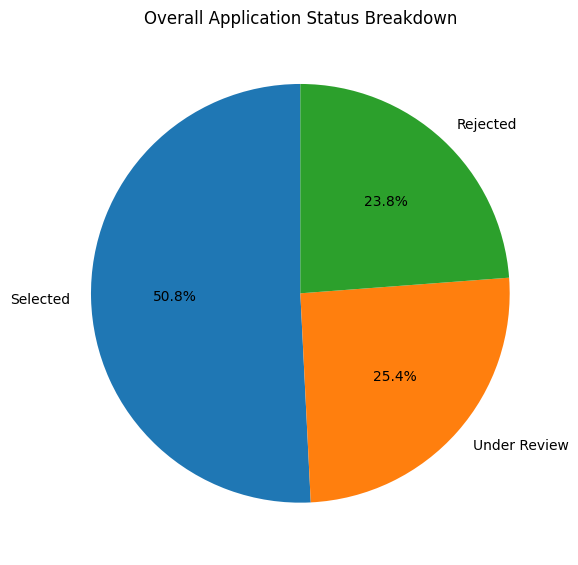

In [174]:
plt.figure(figsize=(6, 6))
status_counts.plot(kind ='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('')
plt.tight_layout()
plt.show()

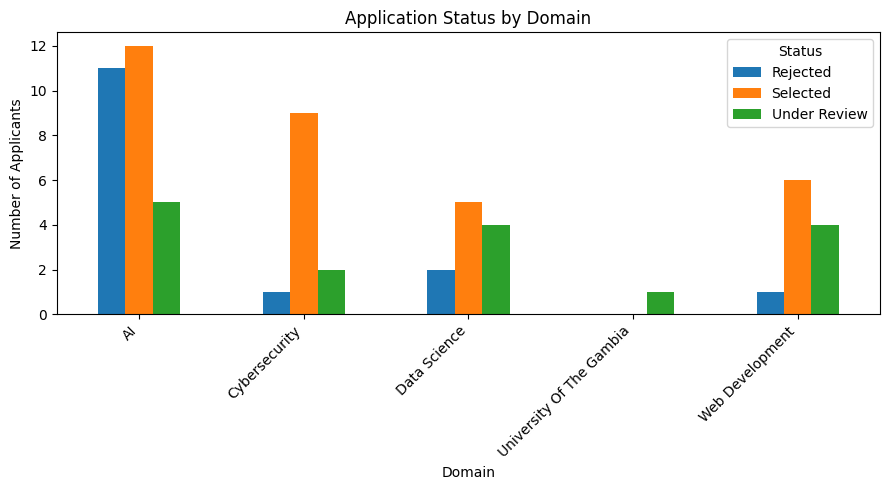

In [175]:
status_by_domain.plot(kind = 'bar', figsize=(9, 5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation =45, ha='right')
plt.legend(title = 'Status')
plt.tight_layout()
plt.show()

**50.8% of the applicants were selected**,while **25.4% of applicants were on review** and **23.8% of the applicants were rejected**.

In [176]:
top_universities = df['University'].value_counts().head(10)
print(top_universities)

University
ALU                         15
University of Kigali        15
University of Rwanda        15
University of The Gambia    10
Not specified                2
UR                           1
UoK                          1
2026-06-01                   1
                             1
Univ. of Kigali              1
Name: count, dtype: int64


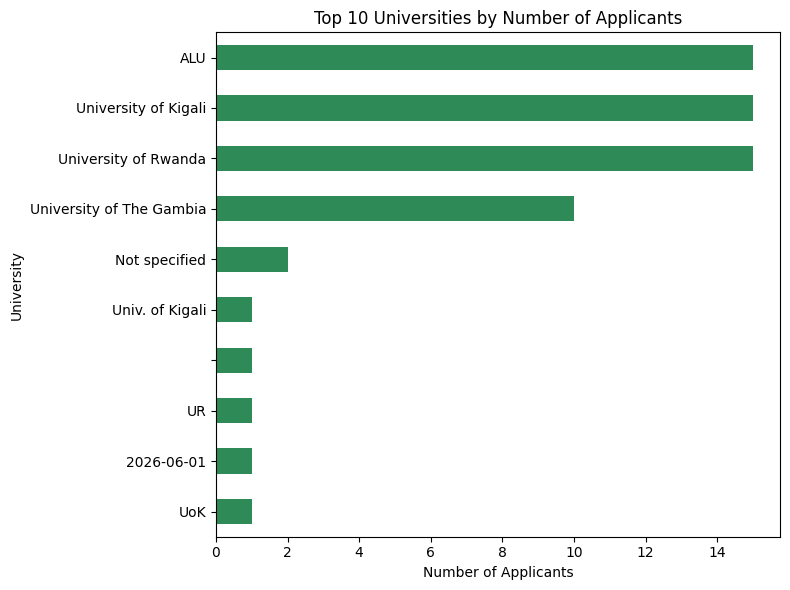

In [177]:
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

The applicant pool was concentrated among a few universities, with ALU, the University of Kigali, and the University of Rwanda accounting for the largest share of applications. This suggests that recruitment outreach or awareness of the opportunity may have been strongest within these institutions.